# Process HRRR-AK GRIB files: Lone Island small domain

**Goal:** combine roughly one week of downloaded April 2019 HRRR-AK forecasts into one NetCDF beside the GRIB data in `hrrrak/`.

| Input | Output | Environment |
| :--- | :--- | :--- |
| `hrrrak/hrrr.201904DD/*.grib2` | `hrrrak/lone_island_small_hrrrak_<first>_<last>.nc` | `glacierbay` |

### Workflow
1. Set paths and optional date limits.
2. Inventory downloads and check missing forecast files.
3. Read selected meteorological fields and retain forecast timing.
4. Combine the small grids, save NetCDF, and reopen it to check.

> **Wait for downloads to finish before the final run.** File discovery takes a snapshot; files arriving later require rerunning the notebook. The exact week is not fixed here. By default, all available April 2019 folders are included, and missing expected files stop processing. No downloads occur in this notebook.

The island reference point is **58.721963, -136.295474** (user-provided map-pin screenshot), not a confirmed station location.

## 1. Check the environment and import tools

> **Viewing on GitHub:** figures, tables, and printed results appear only after the notebook has been run and saved with its outputs. In VS Code, select **glacierbay**, choose **Run All**, then **Save** (`Ctrl+S`). Keep outputs when committing the `.ipynb`; GitHub displays saved results without running Python. For the processing notebook, wait until the selected downloads are complete.

In [7]:
# Embed static figures in the saved notebook for GitHub viewing.
%matplotlib inline

from pathlib import Path
from datetime import datetime, timezone
from tempfile import TemporaryDirectory
import re
import sys

# Use the project's environment rather than another notebook's interpreter.
if Path(sys.prefix).name != "glacierbay":
    raise RuntimeError("Select the glacierbay kernel, restart, and run all cells.")

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

print(f"Python: {sys.executable}")

Python: /home/cassie/programs/miniforge3/envs/glacierbay/bin/python


## 2. Configure paths and dates

The path check supports starting Jupyter from the project folder or its parent workspace. Change `project_dir` if you launch elsewhere.

- **Current sample: April 1–7, 2019 (inclusive initialization dates).** April 8 is only partially downloaded and is excluded.
- Set both dates to `None` only if you want to discover all available April folders, including unfinished days.
- To change the sample, set **both** dates using `"YYYY-MM-DD"`.
- The expected runs and leads below match the current download script; update them together if that script changes.
- Keep `allow_partial = False` for the final dataset. Set it to `True` only for a clearly marked exploratory subset. Neither mode can prove that an actively written file has finished; wait for the downloader.

In [8]:
# Locate this project without hard-coding another project's disk paths.
project_dir = Path.cwd()
if not (project_dir / "hrrrak").is_dir():
    project_dir = project_dir / "glacierbay_alaska"
data_dir = project_dir / "hrrrak"
if not data_dir.is_dir():
    raise FileNotFoundError("Set project_dir to the glacierbay_alaska folder.")

sample_start = "2019-04-01"  # Inclusive initialization dates for our first week.
sample_end = "2019-04-07"
run_hours = tuple(range(0, 24, 3))
lead_hours = (5, 6, 7)
allow_partial = False

reference_latitude = 58.721963
reference_longitude = -136.295474
print(f"Input and output folder: {data_dir.resolve()}")

Input and output folder: /home/cassie/python/repos/glacierbay_alaska/hrrrak


## 3. Inventory the downloads

Each initialization day should have **8 runs × 3 lead times = 24 files** with the current settings. This check also identifies missing whole days between the selected endpoints. A nonempty file is only a candidate: decoding and grid checks happen next.

> With automatic dates, an entirely absent day before the first or after the last discovered folder cannot be detected. Set explicit date limits when you decide the final week.

In [9]:
# Build an expected file list, including absent dates inside the requested interval.
folders = sorted(p for p in data_dir.glob("hrrr.201904[0-9][0-9]") if p.is_dir())
if (sample_start is None) != (sample_end is None):
    raise ValueError("Set both sample dates, or leave both as None.")
if sample_start is None:
    if not folders:
        raise FileNotFoundError("No April 2019 download folders found yet.")
    first_day = pd.to_datetime(folders[0].name.removeprefix("hrrr."), format="%Y%m%d")
    last_day = pd.to_datetime(folders[-1].name.removeprefix("hrrr."), format="%Y%m%d")
else:
    first_day, last_day = pd.Timestamp(sample_start), pd.Timestamp(sample_end)
if first_day > last_day or first_day < pd.Timestamp("2019-04-01") or last_day > pd.Timestamp("2019-04-30"):
    raise ValueError("Select an ordered date range within April 2019.")

files, missing, inventory = [], [], []
for day in pd.date_range(first_day, last_day):
    found = 0
    for hour in run_hours:
        for lead in lead_hours:
            path = data_dir / f"hrrr.{day:%Y%m%d}" / f"hrrr.t{hour:02d}z.wrfsfcf{lead:02d}.ak.grib2"
            if path.is_file() and path.stat().st_size > 0:
                files.append(path)
                found += 1
            else:
                missing.append(path.relative_to(data_dir).as_posix())
    inventory.append({"initialization_day_UTC": str(day.date()), "found": found,
                      "expected": len(run_hours) * len(lead_hours)})
display(pd.DataFrame(inventory))
print(f"Candidate files: {len(files)}; missing/empty: {len(missing)}")
if missing:
    print("Missing examples:", *missing[:8], sep="\n  ")
    if not allow_partial:
        raise RuntimeError("Downloads incomplete. Wait, then rerun; use allow_partial=True only for a trial.")
if not files:
    raise RuntimeError("No nonempty candidate GRIB files are available.")

,initialization_day_UTC,found,expected
0,2019-04-01,24,24
1,2019-04-02,24,24
2,2019-04-03,24,24
3,2019-04-04,24,24
4,2019-04-05,24,24
5,2019-04-06,24,24
6,2019-04-07,24,24


Candidate files: 168; missing/empty: 0


## 4. Read selected variables from each GRIB

A GRIB file may contain several heights and accumulation intervals. We select fields explicitly rather than merging every group or silently overriding conflicts.

| Saved name | Meaning | Treatment |
| :--- | :--- | :--- |
| `temp`, `rh` | 2 m temperature and relative humidity | Native units retained |
| `u10`, `v10`, `wind` | 10 m wind components and calculated speed | Components retained as supplied; no rotation performed |
| `pressure`, `temp_surface`, `terrain_height` | Surface pressure, surface temperature, model terrain | Native units retained |
| `swrad`, `lwrad` | Downward shortwave and longwave flux | Instantaneous fields |
| `precip_rate` | Instantaneous precipitation rate | Native units retained |
| `precip_total` | Accumulated precipitation from initialization to forecast valid time | **Not an hourly amount** |
| `snowdepth`, `swe` | Instantaneous snow depth and snow water equivalent | Native units retained |

The sample files contain both run-total and one-hour precipitation accumulations. Here we explicitly select `startStep=0` for `precip_total`. Its interval is `[forecast_reference_time, time]`; keep this in mind before comparing to observations. No precipitation differencing, unit conversion, station extraction, or missing-value filling happens yet.

**Time layout:** each forecast file becomes one record on `time` (UTC valid time), with its initialization and lead retained. If different forecasts share a valid time, both records remain; use initialization plus lead to distinguish them.

Technical references: [cfgrib GRIB selection](https://github.com/ecmwf/cfgrib) and [xarray concatenation](https://docs.xarray.dev/en/stable/generated/xarray.concat.html).

In [10]:
# Each entry specifies a GRIB short name, height type, level, and time statistic.
fields = {
    "temp": ("2t", "heightAboveGround", 2, "instant"),
    "rh": ("2r", "heightAboveGround", 2, "instant"),
    "u10": ("10u", "heightAboveGround", 10, "instant"),
    "v10": ("10v", "heightAboveGround", 10, "instant"),
    "pressure": ("sp", "surface", 0, "instant"),
    "temp_surface": ("t", "surface", 0, "instant"),
    "terrain_height": ("orog", "surface", 0, "instant"),
    "swrad": ("sdswrf", "surface", 0, "instant"),
    "lwrad": ("sdlwrf", "surface", 0, "instant"),
    "precip_rate": ("prate", "surface", 0, "instant"),
    "precip_total": ("tp", "surface", 0, "accum"),
    "snowdepth": ("sde", "surface", 0, "instant"),
    "swe": ("sdwe", "surface", 0, "instant"),
}


def process_grib(path, index_dir):
    """Load one forecast; fail visibly if a required field or grid is unexpected."""
    before = (path.stat().st_size, path.stat().st_mtime_ns)
    arrays = []
    init_time = lead_time = valid_time = None
    for name, (short, level_type, level, statistic) in fields.items():
        selection = {"shortName": short, "typeOfLevel": level_type,
                     "level": level, "stepType": statistic}
        if name == "precip_total":
            selection["startStep"] = 0  # Select the run-total, not the one-hour total.

        # Cache temporary indexes for this run only; do not create sidecars beside downloads.
        with xr.open_dataset(
            path, engine="cfgrib", backend_kwargs={
                "filter_by_keys": selection,
                "indexpath": str(index_dir / (path.parent.name + "_" + path.name + ".{short_hash}.idx")),
                "errors": "raise",
            },
        ) as group:
            if len(group.data_vars) != 1:
                raise ValueError(f"{path.name}: expected exactly one field for {name}.")
            timing = (group.time.values, group.step.values, group.valid_time.values)
            if init_time is None:
                init_time, lead_time, valid_time = timing
            elif not all(np.array_equal(a, b) for a, b in zip(timing, (init_time, lead_time, valid_time))):
                raise ValueError(f"Inconsistent forecast times in {path}")
            # Load before closing the file; keep units and GRIB attributes on each variable.
            array = next(iter(group.data_vars.values())).load().rename(name)
            if array.dims != ("y", "x"):
                raise ValueError(f"{name}: expected a 2-D small grid, got {array.dims}.")
            array = array.reset_coords(drop=True)
            arrays.append(array)
            latitude = group.latitude.load().reset_coords(drop=True)
            longitude = ((group.longitude.load().reset_coords(drop=True) + 180) % 360) - 180
            if name == "temp":
                grid_latitude, grid_longitude = latitude, longitude
            elif not (np.allclose(latitude, grid_latitude) and np.allclose(longitude, grid_longitude)):
                raise ValueError(f"Grid differs between variables in {path}")

    # Merge strictly: incompatible values are errors, not silently overridden.
    result = xr.merge(arrays, compat="equals", join="exact")
    result = result.assign_coords(latitude=grid_latitude, longitude=grid_longitude)
    # This workflow is deliberately restricted to the existing Lone Island small subset.
    if result.sizes["y"] > 10 or result.sizes["x"] > 10:
        raise ValueError("Grid is larger than the intended small domain; check download bounds.")
    if float(abs(result.latitude - reference_latitude).max()) > 0.15 or float(abs(result.longitude - reference_longitude).max()) > 0.3:
        raise ValueError("Grid is not near the Lone Island reference point.")
    expected_init = pd.to_datetime(path.parent.name[5:], format="%Y%m%d") + pd.Timedelta(hours=int(path.name[6:8]))
    expected_lead = pd.Timedelta(hours=int(re.search(r"wrfsfcf(\d+)", path.name).group(1)))
    if pd.Timestamp(init_time) != expected_init or pd.Timedelta(lead_time) != expected_lead:
        raise ValueError(f"Filename and decoded timing differ: {path}")
    if not np.array_equal(valid_time, init_time + lead_time):
        raise ValueError(f"Invalid forecast timing in {path}")
    result["wind"] = np.hypot(result.u10, result.v10)
    result.wind.attrs = {"long_name": "10 m wind speed from supplied components", "units": result.u10.attrs["units"], "standard_name": "wind_speed"}
    result.precip_total.attrs["accumulation_interval"] = "forecast_reference_time to time (UTC)"

    # Expand scalar forecast timing into one record, and preserve source-file provenance.
    result = result.expand_dims(time=[valid_time])
    result = result.assign_coords(
        forecast_reference_time=("time", [init_time]),
        forecast_period=("time", [lead_time]),
        source_file=("time", [path.relative_to(data_dir).as_posix()]),
    )
    if before != (path.stat().st_size, path.stat().st_mtime_ns):
        raise RuntimeError(f"File changed while being read; wait for download: {path}")
    return result

## 5. Combine the forecasts and inspect the result

Processing is sequential and intended for a small domain and a short period. Every selected file must decode successfully; failures stop the run rather than quietly dropping records. Matching grid coordinates and variable units are checked before concatenation. Temporary indexes are automatically removed.

The data stay on the model grid (`y`, `x`) with 2-D latitude and longitude coordinates. Longitudes are expressed as negative degrees west. This is a model subset, not a station time series.

In [11]:
records = []
with TemporaryDirectory(prefix="glacierbay_grib_") as cache:
    for number, path in enumerate(files, start=1):
        try:
            record = process_grib(path, Path(cache))
            if records:
                xr.testing.assert_equal(record.latitude, records[0].latitude)
                xr.testing.assert_equal(record.longitude, records[0].longitude)
                for name in fields:
                    if record[name].attrs.get("units") != records[0][name].attrs.get("units"):
                        raise ValueError(f"Units changed for {name}")
            records.append(record)
        except Exception as error:
            raise RuntimeError(f"Failed to process {path}. Check download and field availability.") from error
        if number == 1 or number % 24 == 0 or number == len(files):
            print(f"Processed {number}/{len(files)}")

# Exact joins prevent accidental expansion to a different spatial grid.
final_ds = xr.concat(records, dim="time", data_vars="all", coords="minimal",
                     compat="equals", join="exact", combine_attrs="override").sortby("time")
final_ds.time.attrs.update(standard_name="time", long_name="Forecast valid time (UTC)")
final_ds.forecast_reference_time.attrs.update(standard_name="forecast_reference_time", long_name="Initialization time (UTC)")
final_ds.forecast_period.attrs.update(standard_name="forecast_period", long_name="Forecast lead time")
final_ds.latitude.attrs.update(standard_name="latitude", units="degrees_north")
final_ds.longitude.attrs.update(standard_name="longitude", units="degrees_east")
final_ds.attrs.update(
    title="HRRR-AK Lone Island small-domain forecasts",
    model="HRRR-AK", time_zone="UTC",
    reference_latitude=reference_latitude, reference_longitude=reference_longitude,
    coordinate_provenance="User-provided map-pin screenshot; exact station location unconfirmed",
    initialization_date_start=str(first_day.date()), initialization_date_end=str(last_day.date()),
    date_selection="Explicit dates" if sample_start is not None else "Automatically discovered April 2019 folders; week not confirmed",
    missing_expected_files=len(missing), partial_download=int(bool(missing)),
    missing_file_list="\n".join(missing),
    history=f"Created {datetime.now(timezone.utc).isoformat()} by 2_process_hrrrak_grib_files.ipynb",
    processing_notes="Native units retained. Precipitation total starts at initialization. No station matching or time averaging.",
)
if not all("units" in final_ds[name].attrs for name in final_ds.data_vars):
    raise ValueError("A variable lost its units during combination.")
display(final_ds)
display(pd.DataFrame([
    {"variable": name, "units": value.attrs.get("units", "not specified"),
     "missing_values": int(value.isnull().sum())}
    for name, value in final_ds.data_vars.items()
]))
print("Valid-time coverage (UTC):", final_ds.time.values.min(), "to", final_ds.time.values.max())
print("Duplicate valid times (retained):", int(pd.Index(final_ds.time.values).duplicated().sum()))

Processed 1/168
Processed 24/168
Processed 48/168
Processed 72/168
Processed 96/168
Processed 120/168
Processed 144/168
Processed 168/168


<xarray.Dataset> Size: 117kB
Dimensions:                  (time: 168, y: 3, x: 3)
Coordinates:
  * time                     (time) datetime64[ns] 1kB 2019-04-01T05:00:00 .....
    forecast_reference_time  (time) datetime64[ns] 1kB 2019-04-01 ... 2019-04...
    forecast_period          (time) timedelta64[ns] 1kB 05:00:00 ... 07:00:00
    source_file              (time) <U42 28kB 'hrrr.20190401/hrrr.t00z.wrfsfc...
    latitude                 (y, x) float64 72B 58.69 58.69 ... 58.74 58.75
    longitude                (y, x) float64 72B -136.3 -136.3 ... -136.3 -136.2
Dimensions without coordinates: y, x
Data variables: (12/14)
    temp                     (time, y, x) float32 6kB 283.6 283.8 ... 280.1
    rh                       (time, y, x) float32 6kB 50.7 50.2 ... 90.9 89.4
    u10                      (time, y, x) float32 6kB 3.406 4.594 ... -4.852
    v10                      (time, y, x) float32 6kB 2.294 0.6693 ... 4.817
    pressure                 (time, y, x) float32 6kB 1.031e+05 ... 9.982e+04
    temp_surface             (time, y, x) float32 6kB 281.3 281.5 ... 282.6
    ...                       ...
    lwrad                    (time, y, x) float32 6kB 262.1 262.5 ... 332.7
    precip_rate              (time, y, x) float32 6kB 0.0 0.0 ... 0.00019
    precip_total             (time, y, x) float32 6kB 0.0 0.0 ... 3.795 3.283
    snowdepth                (time, y, x) float32 6kB 0.0 0.0 0.0 ... 0.0 0.0
    swe                      (time, y, x) float32 6kB 0.0 0.0 0.0 ... 0.0 0.0
    wind                     (time, y, x) float32 6kB 4.107 4.642 ... 6.837
Attributes: (12/32)
    GRIB_paramId:                    167
    GRIB_dataType:                   fc
    GRIB_numberOfPoints:             9
    GRIB_typeOfLevel:                heightAboveGround
    GRIB_stepUnits:                  1
    GRIB_stepType:                   instant
    ...                              ...
    date_selection:                  Explicit dates
    missing_expected_files:          0
    partial_download:                0
    missing_file_list:               
    history:                         Created 2026-10-15T11:30:53.246850+00:00...
    processing_notes:                Native units retained. Precipitation tot...

,variable,units,missing_values
0,temp,K,0
1,rh,%,0
2,u10,m s**-1,0
3,v10,m s**-1,0
4,pressure,Pa,0
5,temp_surface,K,0
6,terrain_height,m,0
7,swrad,W m**-2,0
8,lwrad,W m**-2,0
9,precip_rate,kg m**-2 s**-1,0


Valid-time coverage (UTC): 2019-04-01T05:00:00.000000000 to 2019-04-08T04:00:00.000000000
Duplicate valid times (retained): 0


## 6. Save beside the GRIB files and reopen

The filename records the **initialization-date range**, which can differ from valid-time coverage. A trial with missing files receives a `_partial` suffix. This snapshot can be regenerated after downloads finish; the same output is replaced on rerun. Writing a temporary file first prevents leaving a half-written final NetCDF if serialization fails.

We retain each variable's native units and GRIB metadata. This NetCDF contains selected analysis fields, not every message from the source GRIB files.

In [12]:
suffix = "_partial" if missing else ""
output_path = data_dir / f"lone_island_small_hrrrak_{first_day:%Y%m%d}_{last_day:%Y%m%d}{suffix}.nc"
temporary_path = output_path.with_suffix(".nc.tmp")

# Compress the small floating-point fields without changing their values.
encoding = {name: {"zlib": True, "complevel": 4} for name in final_ds.data_vars}
try:
    final_ds.to_netcdf(temporary_path, engine="netcdf4", encoding=encoding)
    # Decode and compare values, coordinates, and attributes before publishing the file.
    with xr.open_dataset(temporary_path, engine="netcdf4", decode_timedelta=True) as saved:
        xr.testing.assert_identical(final_ds, saved.load())
    temporary_path.replace(output_path)
finally:
    temporary_path.unlink(missing_ok=True)
print(f"Saved and verified: {output_path.resolve()}")
print(f"Size: {output_path.stat().st_size / 1024:.1f} KiB")

Saved and verified: /home/cassie/python/repos/glacierbay_alaska/hrrrak/lone_island_small_hrrrak_20190401_20190407.nc
Size: 165.4 KiB


## 7. Quick visual check

Plot the first temperature grid in degrees Celsius for readability. The NetCDF itself retains Kelvin. This check shows the small model domain; it is not an evaluation against station observations.

**Next:** confirm the final date range and completeness, check variable units and precipitation intervals, then align model forecasts with verified station coordinates and observation timestamps.

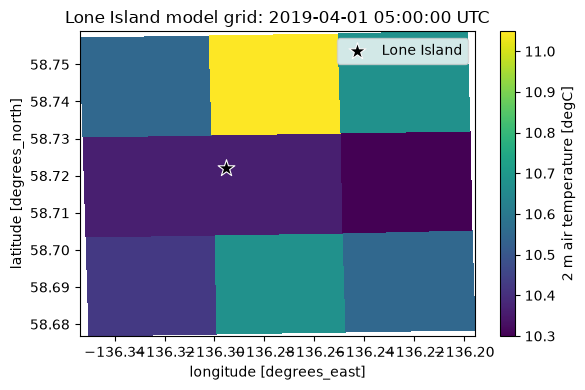

In [14]:
# Reopen the actual saved NetCDF and display its first 2 m temperature field.
with xr.open_dataset(output_path, decode_timedelta=True) as saved:
    first_temperature = (saved.temp.isel(time=0) - 273.15).load()
    first_temperature.attrs.update(long_name="2 m air temperature", units="degC")

    fig, ax = plt.subplots(figsize=(6, 4))
    first_temperature.plot(ax=ax, x="longitude", y="latitude")

    # Lone Island reference point from the map pin.
    ax.scatter(
        -136.295474, 58.721963,
        marker="*",
        s=160,
        color="black",
        edgecolor="white",
        linewidth=0.8,
        label="Lone Island",
        zorder=5,
    )
    ax.legend(loc="best")

    ax.set_title(f"Lone Island model grid: {pd.Timestamp(saved.time.values[0])} UTC")
    fig.tight_layout()
    plt.show()